# Day 9
## MUSIC Algorithm Simulation Using Synthetic Data

**Role:** RF & DSP Engineer  
**Task:** Implement a basic MUSIC (Multiple Signal Classification) simulation to estimate signal arrival directions using synthetic antenna-array data.

### Objective
Generate synthetic signals, simulate an antenna array, add noise, calculate the covariance matrix, perform eigenvalue decomposition, and plot the MUSIC spectrum.

**Scope:** Synthetic data only. This notebook does not receive or analyze real radio signals or validate real-world antenna performance.

## Step 1 — Import libraries
NumPy is used for calculations and Matplotlib for plotting.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Setup ready!")

NumPy version: 2.5.3
Setup ready!


## Step 2 — Set simulation parameters

We model 8 virtual antennas, 2 independent signal sources, and 200 samples per source. The expected test angles are −20° and +30°.

In [2]:
np.random.seed(42)

num_antennas = 8
num_sources = 2
num_samples = 200
true_angles = [-20, 30]
wavelength = 1.0
spacing = wavelength / 2
noise_level = 0.1
antenna_positions = np.arange(num_antennas)

print("Number of antennas:", num_antennas)
print("Number of signal sources:", num_sources)
print("Samples per source:", num_samples)
print("Expected test angles:", true_angles)

Number of antennas: 8
Number of signal sources: 2
Samples per source: 200
Expected test angles: [-20, 30]


## Step 3 — Generate synthetic source signals

The signals are complex-valued random data. Dividing by √2 gives each source unit average power in expectation when real and imaginary parts are independent standard normal variables.

In [3]:
source_signals = (
    np.random.randn(num_sources, num_samples)
    + 1j * np.random.randn(num_sources, num_samples)
) / np.sqrt(2)

print("Source signal shape:", source_signals.shape)

Source signal shape: (2, 200)


## Step 4 — Build the antenna steering matrix

The steering matrix models phase differences across the array for each assumed arrival angle. The angle convention is measured from broadside, with half-wavelength spacing.

In [4]:
steering_matrix = np.zeros((num_antennas, num_sources), dtype=complex)

for i, angle in enumerate(true_angles):
    angle_rad = np.deg2rad(angle)
    steering_matrix[:, i] = np.exp(
        -1j * 2 * np.pi * spacing * antenna_positions
        * np.sin(angle_rad) / wavelength
    )

print("Steering matrix shape:", steering_matrix.shape)

Steering matrix shape: (8, 2)


## Step 5 — Simulate received signals with noise

The received data combines source signals through the steering matrix and adds complex Gaussian noise.

In [5]:
noise = noise_level * (
    np.random.randn(num_antennas, num_samples)
    + 1j * np.random.randn(num_antennas, num_samples)
) / np.sqrt(2)

received_signals = steering_matrix @ source_signals + noise
print("Received signal shape:", received_signals.shape)

Received signal shape: (8, 200)


## Step 6 — Calculate the covariance matrix

The covariance matrix summarizes relationships between signals at different antenna elements.

In [6]:
covariance_matrix = (
    received_signals @ received_signals.conj().T
) / num_samples
print("Covariance matrix shape:", covariance_matrix.shape)

Covariance matrix shape: (8, 8)


## Step 7 — Eigenvalue decomposition

We sort eigenvalues and their eigenvectors from largest to smallest. The two largest eigenvectors form the estimated signal subspace; the remaining six form the noise subspace in this simulation.

In [7]:
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("Eigenvalues (largest to smallest):")
print(np.round(eigenvalues, 3))
print("Eigenvectors shape:", eigenvectors.shape)

Eigenvalues (largest to smallest):
[9.506e+00 6.114e+00 1.200e-02 1.100e-02 1.000e-02 1.000e-02 9.000e-03
 8.000e-03]
Eigenvectors shape: (8, 8)


## Step 8 — Select the noise subspace

In [8]:
noise_subspace = eigenvectors[:, num_sources:]
print("Noise subspace shape:", noise_subspace.shape)
print("Number of noise eigenvectors:", noise_subspace.shape[1])

Noise subspace shape: (8, 6)
Number of noise eigenvectors: 6


## Step 9 — Calculate the MUSIC spectrum

We scan candidate angles from −90° to +90°. The MUSIC score becomes large when a steering vector is nearly orthogonal to the estimated noise subspace.

In [9]:
angle_scan = np.arange(-90, 91, 1)
music_spectrum = []

for angle in angle_scan:
    angle_rad = np.deg2rad(angle)
    steering_vector = np.exp(
        -1j * 2 * np.pi * spacing * antenna_positions
        * np.sin(angle_rad) / wavelength
    ).reshape(-1, 1)

    denominator = (
        steering_vector.conj().T
        @ noise_subspace
        @ noise_subspace.conj().T
        @ steering_vector
    ).item()

    music_value = 1 / max(abs(denominator), 1e-12)
    music_spectrum.append(music_value)

music_spectrum = np.array(music_spectrum)
music_spectrum_db = 10 * np.log10(music_spectrum / np.max(music_spectrum))

print("MUSIC spectrum calculated.")
print("Number of scanned angles:", len(angle_scan))
print("Spectrum shape:", music_spectrum_db.shape)

MUSIC spectrum calculated.
Number of scanned angles: 181
Spectrum shape: (181,)


## Step 10 — Estimate the two strongest separated local peaks

This simple peak picker is for demonstration. It selects local peaks separated by at least 5°. Check the estimates against the plotted spectrum and expected angles.

In [10]:
local_peaks = []
for i in range(1, len(music_spectrum_db) - 1):
    if (music_spectrum_db[i] > music_spectrum_db[i - 1]
            and music_spectrum_db[i] >= music_spectrum_db[i + 1]):
        local_peaks.append(i)

local_peaks.sort(key=lambda i: music_spectrum_db[i], reverse=True)
selected_peaks = []
for index in local_peaks:
    if all(abs(angle_scan[index] - angle_scan[j]) >= 5 for j in selected_peaks):
        selected_peaks.append(index)
    if len(selected_peaks) == num_sources:
        break

estimated_angles = sorted([int(angle_scan[i]) for i in selected_peaks])
print("Expected angles:", true_angles)
print("Estimated angles:", estimated_angles)

Expected angles: [-20, 30]
Estimated angles: [-20, 30]


## Step 11 — Plot the MUSIC spectrum

Peaks near the expected test angles indicate that the simulation estimates the chosen directions. Dashed lines mark expected angles, not real measurements.

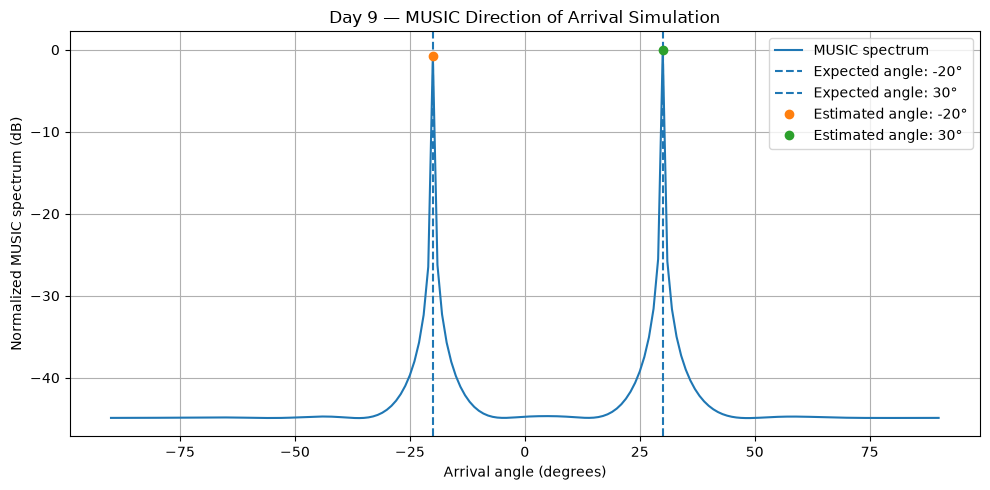

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(angle_scan, music_spectrum_db, label="MUSIC spectrum")

for angle in true_angles:
    plt.axvline(x=angle, linestyle="--", label=f"Expected angle: {angle}°")

for angle in estimated_angles:
    index = np.where(angle_scan == angle)[0][0]
    plt.plot(angle, music_spectrum_db[index], "o", label=f"Estimated angle: {angle}°")

plt.xlabel("Arrival angle (degrees)")
plt.ylabel("Normalized MUSIC spectrum (dB)")
plt.title("Day 9 — MUSIC Direction of Arrival Simulation")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Results and observations

- 8 virtual antenna elements and 2 independent synthetic sources are used.
- Covariance matrix shape: `(8, 8)`.
- Noise subspace shape: `(8, 6)`.
- The MUSIC spectrum scans 181 candidate angles from −90° to +90°.
- Compare the estimated peaks with the expected test angles of −20° and +30°.

## Limitations

- Synthetic data only; no real RF data or hardware testing.
- The number of sources is assumed to be known.
- The model assumes a uniform linear array, ideal element positions, narrowband signals, and independent sources.
- The simple peak picker is for demonstration and may need improvement for difficult or noisy cases.

## Conclusion

This notebook demonstrates a basic MUSIC workflow: synthetic signal generation, antenna-array modelling, covariance matrix calculation, eigenvalue decomposition, noise-subspace selection, spectrum scanning, and angle estimation.

**Deliverable:** MUSIC algorithm simulation demonstration using synthetic data. Mark as completed after running all cells and checking the plot and printed estimated angles.